# NB11: fMRIPrep QC

> **Local pipeline required.** This notebook inspects fMRIPrep outputs and cannot run in Google Colab. See NB00--NB06 and NB08 for Colab-compatible notebooks.

## Purpose
Quality control of fMRIPrep BOLD preprocessing outputs. Verify BOLD-to-T1w
registration, motion parameters, and confound estimates.

## HTML Reports
fMRIPrep generates comprehensive HTML QC reports. Open them directly:
```bash
open derivatives/fmriprep/sub-PAT16.html
```

## QC Checklist
- [ ] BOLD-to-T1w registration (BBR) converged
- [ ] SyN SDC correction plausible in orbitofrontal/temporal regions
- [ ] Framewise displacement < 0.5 mm for majority of volumes
- [ ] No excessive signal dropout or ghosting
- [ ] Confound time series look reasonable

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DERIV_ROOT = REPO_ROOT / 'derivatives'
FMRIPREP_DIR = DERIV_ROOT / 'fmriprep'
SUBJECTS = ['PAT16']
SESSIONS = ['preop', 'postop']

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 1. Output Inventory

In [2]:
expected_patterns = [
    '*_space-T1w_desc-preproc_bold.nii.gz',
    '*_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz',
    '*_desc-confounds_timeseries.tsv',
    '*_space-T1w_desc-brain_mask.nii.gz',
    '*_space-T1w_boldref.nii.gz',
]

for sub in SUBJECTS:
    print(f'\n=== sub-{sub} ===')
    for ses in SESSIONS:
        func_dir = FMRIPREP_DIR / f'sub-{sub}' / f'ses-{ses}' / 'func'
        print(f'  ses-{ses}:')
        if not func_dir.exists():
            print('    Not yet run')
            continue
        for pattern in expected_patterns:
            matches = list(func_dir.glob(pattern))
            mark = 'OK' if matches else 'MISSING'
            name = matches[0].name if matches else pattern
            print(f'    [{mark}] {name}')


=== sub-PAT16 ===
  ses-preop:
    [OK] sub-PAT16_ses-preop_task-rest_space-T1w_desc-preproc_bold.nii.gz
    [OK] sub-PAT16_ses-preop_task-rest_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
    [OK] sub-PAT16_ses-preop_task-rest_desc-confounds_timeseries.tsv
    [OK] sub-PAT16_ses-preop_task-rest_space-T1w_desc-brain_mask.nii.gz
    [OK] sub-PAT16_ses-preop_task-rest_space-T1w_boldref.nii.gz
  ses-postop:
    [OK] sub-PAT16_ses-postop_task-rest_space-T1w_desc-preproc_bold.nii.gz
    [OK] sub-PAT16_ses-postop_task-rest_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz
    [OK] sub-PAT16_ses-postop_task-rest_desc-confounds_timeseries.tsv
    [OK] sub-PAT16_ses-postop_task-rest_space-T1w_desc-brain_mask.nii.gz
    [OK] sub-PAT16_ses-postop_task-rest_space-T1w_boldref.nii.gz


## 2. Motion Parameters (Framewise Displacement)

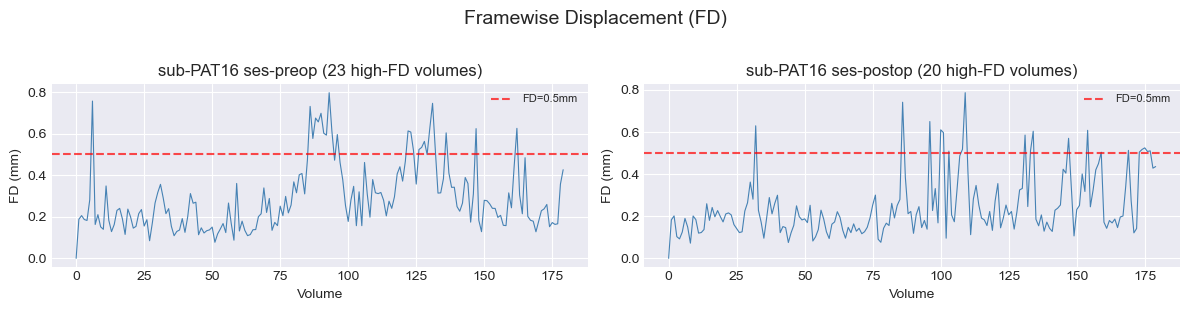

In [3]:
try:
    import pandas as pd

    fig, axes = plt.subplots(len(SUBJECTS), len(SESSIONS),
                             figsize=(6 * len(SESSIONS), 3 * len(SUBJECTS)),
                             squeeze=False)
    fig.suptitle('Framewise Displacement (FD)', fontsize=14, y=1.02)

    for i, sub in enumerate(SUBJECTS):
        for j, ses in enumerate(SESSIONS):
            ax = axes[i][j]
            func_dir = FMRIPREP_DIR / f'sub-{sub}' / f'ses-{ses}' / 'func'
            conf_files = list(func_dir.glob('*_desc-confounds_timeseries.tsv')) if func_dir.exists() else []

            if conf_files:
                df = pd.read_csv(conf_files[0], sep='\t')
                if 'framewise_displacement' in df.columns:
                    fd = df['framewise_displacement'].fillna(0)
                    ax.plot(fd, color='steelblue', linewidth=0.8)
                    ax.axhline(0.5, color='red', linestyle='--', alpha=0.7, label='FD=0.5mm')
                    n_bad = int((fd > 0.5).sum())
                    ax.set_title(f'sub-{sub} ses-{ses} ({n_bad} high-FD volumes)')
                    ax.set_ylabel('FD (mm)')
                    ax.set_xlabel('Volume')
                    ax.legend(fontsize=8)
                else:
                    ax.text(0.5, 0.5, 'FD column not found', ha='center',
                            va='center', transform=ax.transAxes)
            else:
                ax.text(0.5, 0.5, 'Not available', ha='center',
                        va='center', transform=ax.transAxes)
                ax.set_title(f'sub-{sub} ses-{ses}')

    plt.tight_layout()
    plt.show()

except ImportError:
    print('pandas not available')
except Exception as e:
    print(f'Motion QC not available: {e}')

## 3. BOLD-to-T1w Registration Check

Overlay the BOLD reference on the T1w to verify alignment.
For interactive 3D inspection:
```bash
bash scripts/freeview_registration.sh --subject PAT16 --session preop
```

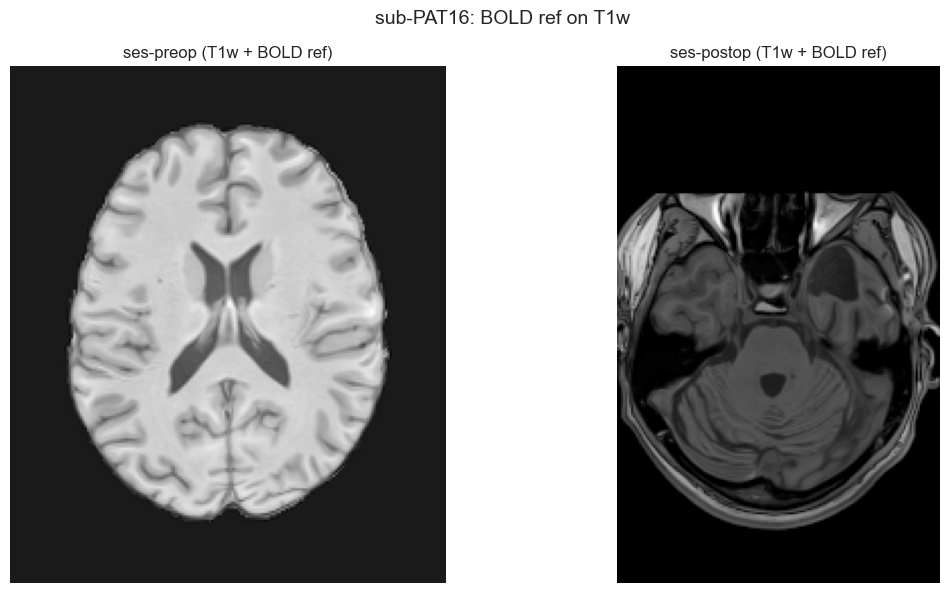

In [4]:
try:
    import nibabel as nib

    for sub in SUBJECTS:
        fig, axes = plt.subplots(1, len(SESSIONS), figsize=(6 * len(SESSIONS), 6))
        if len(SESSIONS) == 1:
            axes = [axes]
        fig.suptitle(f'sub-{sub}: BOLD ref on T1w', fontsize=14)

        for idx, ses in enumerate(SESSIONS):
            ax = axes[idx]
            anat_dir = FMRIPREP_DIR / f'sub-{sub}' / f'ses-{ses}' / 'anat'
            func_dir = FMRIPREP_DIR / f'sub-{sub}' / f'ses-{ses}' / 'func'

            t1w_files = list(anat_dir.glob('*_desc-preproc_T1w.nii.gz')) if anat_dir.exists() else []
            bold_files = list(func_dir.glob('*_space-T1w_boldref.nii.gz')) if func_dir.exists() else []

            if t1w_files and bold_files:
                t1w = np.asarray(nib.load(str(t1w_files[0])).dataobj)
                bold = np.asarray(nib.load(str(bold_files[0])).dataobj)
                mid = t1w.shape[2] // 2
                ax.imshow(np.rot90(t1w[:, :, mid]), cmap='gray')
                if bold.shape[2] == t1w.shape[2]:
                    ax.imshow(np.rot90(bold[:, :, mid]), cmap='hot', alpha=0.3)
                ax.set_title(f'ses-{ses} (T1w + BOLD ref)')
            else:
                ax.text(0.5, 0.5, 'Not available', ha='center', va='center',
                        transform=ax.transAxes, fontsize=12)
                ax.set_title(f'ses-{ses}')
            ax.axis('off')

        plt.tight_layout()
        plt.show()

except Exception as e:
    print(f'Registration QC not available: {e}')

## 4. Confound Summary

Key confounds to inspect before extracting functional connectivity.

In [5]:
try:
    import pandas as pd

    confound_cols = [
        'framewise_displacement', 'dvars',
        'trans_x', 'trans_y', 'trans_z',
        'rot_x', 'rot_y', 'rot_z',
    ]

    for sub in SUBJECTS:
        print(f'\n=== sub-{sub} ===')
        for ses in SESSIONS:
            func_dir = FMRIPREP_DIR / f'sub-{sub}' / f'ses-{ses}' / 'func'
            conf_files = list(func_dir.glob('*_desc-confounds_timeseries.tsv')) if func_dir.exists() else []
            if not conf_files:
                print(f'  ses-{ses}: not available')
                continue

            df = pd.read_csv(conf_files[0], sep='\t')
            print(f'  ses-{ses}: {len(df)} volumes, {len(df.columns)} confound columns')
            available = [c for c in confound_cols if c in df.columns]
            if available:
                summary = df[available].describe().loc[['mean', 'std', 'max']]
                print(summary.to_string(float_format='{:.4f}'.format))

except ImportError:
    print('pandas not available')
except Exception as e:
    print(f'Confound summary not available: {e}')


=== sub-PAT16 ===
  ses-preop: 180 volumes, 213 confound columns
      framewise_displacement   dvars  trans_x  trans_y  trans_z   rot_x   rot_y  rot_z
mean                  0.2914 45.2553   0.1598  -0.0499   0.2282 -0.0081 -0.0029 0.0006
std                   0.1613  7.2187   0.1083   0.0669   0.2726  0.0074  0.0022 0.0008
max                   0.7976 68.7109   0.3303   0.1301   0.7940  0.0142  0.0028 0.0024
  ses-postop: 180 volumes, 213 confound columns
      framewise_displacement   dvars  trans_x  trans_y  trans_z   rot_x  rot_y  rot_z
mean                  0.2473 47.1436  -0.0567   0.0530  -0.4726 -0.0059 0.0030 0.0006
std                   0.1446  9.3223   0.0352   0.0512   0.3820  0.0045 0.0020 0.0006
max                   0.7868 74.9347   0.0200   0.1576   0.1034  0.0042 0.0063 0.0020
